In [55]:
# read in packages
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

In [64]:
# read in data
mbta_df = gpd.read_file("mbtabus/MBTABUSSTOPS_PT.shp") # geometry data
rta_df = gpd.read_file("RTA_Stops/RTA_Stops.shp")
tracts_df = gpd.read_file("CENSUS2020/CENSUS2020TRACTS_POLY.shp")
pop_df = pd.read_csv("ACS_Population_Data/ACSDP5Y2024.DP05-Data.csv") # census tract
#vehicle_df = pd.read_csv("MVC_Snapshot_Black_Group.csv") block group
income_df = pd.read_csv("ACS_Income_Data/ACSST5Y2024.S1901-Data.csv")

# find size of each dataset
print(mbta_df.shape)
print(pop_df.shape)
print(tracts_df.shape)
print(income_df.shape) # want just total med income and tract variable

(7810, 5)
(1621, 435)
(1613, 19)
(1621, 131)


In [66]:
# summary of variables
# Estimate!!Mean income (dollars)!!HOUSEHOLD INCOME!!All households
# Estimate!!SEX AND AGE!!Total population
pop_df.describe(include='all') 
mbta_df.describe(include='all') 
tracts_df.describe(include='all') 
income_df.describe(include='all') 

# check for missing data, has none!!
pop_df.isna().sum()
mbta_df.isna().sum()
tracts_df.isna().sum()
income_df.isna().sum()


GEO_ID               0
NAME                 0
S1901_C01_001E       0
S1901_C01_001M       0
S1901_C01_002E       0
                  ... 
S1901_C04_015E       0
S1901_C04_015M       0
S1901_C04_016E       0
S1901_C04_016M       0
Unnamed: 130      1621
Length: 131, dtype: int64

In [38]:
# select columns
mbta_df = mbta_df.loc[:, ["STOP_NAME", "geometry"]]
rta_df = rta_df.loc[:, ["stop_name", "Agency", "geometry"]]
tracts_df = tracts_df.loc[:, ["TRACTCE20", "POP20", "GEOID20", "geometry"]]

# make rtas the same crs
rta_df = rta_df.to_crs(tracts_df.crs)

# rework and combine bus stop datasets
mbta_df = mbta_df.rename(columns={"STOP_NAME": "stop_name"})
mbta_df = mbta_df.assign(Agency="MBTA")

stops_df = pd.concat([mbta_df, rta_df])

In [70]:
income_df = income_df.loc[:, ["GEO_ID", "NAME", "S1901_C01_012E"]]
income_df["GEO_ID"] = income_df["GEO_ID"].str.split("US").str[-1]

# stops_df = gpd.read_file("combined_bus_loc.shp")

joined = stops_df.merge(income_df, left_on="GEOID20", right_on="GEO_ID", how="left")
joined = joined.dropna()

# joined.isna().sum() # 1256
# len(joined)

# scatterplot
# sns.relplot(x='stop_count', y='S1902_C03_001E', data=joined)

# plt.title('Transit Availability vs Median Income by Census Tract')
# plt.xlabel('Number of Bus Stops in Tract')
# plt.ylabel('Median Income')


# map
#joined.plot(column="S1901_C01_012E", cmap="magma_r", legend=True)

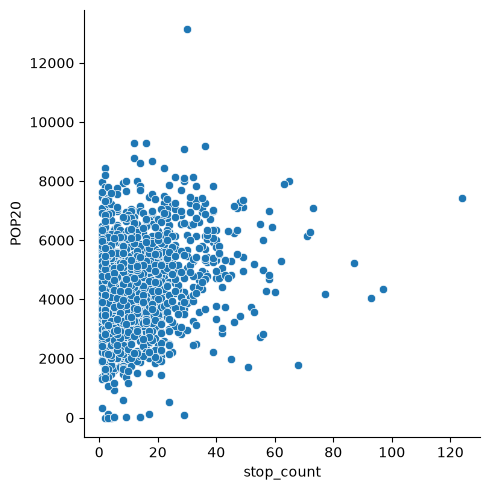

In [71]:
sns.relplot(x='stop_count', y='POP20', data=joined)

In [ ]:
# create 2 viz for each intended dataset cambo

# 1: MBTA & Tracts viz?
#       - map of # of stops for each tract
#       - bar plot of # of stops for each tract idk sum of stops per tract
# 2: MBTA & Tracts & Income viz
#       - scatterplot of # of stops vs med income for each tract
#       - map w stops and income lol (low income?)
# 3: MBTA & Tracts & Population viz
#       - scatterplot of # of stops vs population for each tract
#       - map w stops and population?

In [ ]:
# vehicles missing data
# vehicle_nas = vehicle_df[vehicle_df["BLOCKGROUP"].isna()]
# vehicle_nas.describe(include='all')

In [ ]:
# test ideas

# 1. CRS consistency: the MBTA, RTA and tract layers all use the same CRS before the spatial join.
# 2. No stops lost or double-counted: compare the number of joined rows with the number of stops. 
#    Any stop that matched no tract or two tracts should be explained, not silently dropped or counted twice.
# 3. Counts add up: the total of stop_count across all tracts equals the number of joined stops.
# 4. Valid count values: every stop_count is a whole number of 0 or more, and tracts with no stops show 0, not NaN.
# 5. Toy-data check of the counting logic: build a few hand-made squares and points where you know the answer, 
#    and confirm the counts come out exactly right.
# 6. One row per tract: GEOID20 is unique, and the number of tracts stays the same before and after each merge.
# 7. Income merge matches: most tracts actually get an income value after the merge. This catches the GEO_ID vs GEOID20 format mismatch.
# 8. Clean income values: income is numeric, the ACS description row and placeholders like "-" or "250,000+" are handled, and values fall in a plausible range.
# 9. Output file round-trip: reading combined_bus_loc.shp back gives the same rows, counts and geometry you wrote, and GEOID20 keeps its leading zeros.
# 10. Spot-check known tracts: a dense downtown Boston tract should have many stops and a rural tract few or none. 
#     This is a quick check that the results look reasonable.